In [8]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt

In [9]:
# 指定文件夹路径
folder_path = r"D:\桌面\绿色货币\数据总库\R数据抓取加密货币数据"
# 获取所有符合条件的 CSV 文件路径并读取合并
file_paths = sorted(glob.glob(os.path.join(folder_path, "crypto_full_20*_Daily_data.csv")))
df = pd.concat((pd.read_csv(file) for file in file_paths), ignore_index=True)
df.columns

Index(['id', 'slug', 'name', 'symbol', 'timestamp', 'ref_cur_id',
       'ref_cur_name', 'time_open', 'time_close', 'time_high', 'time_low',
       'open', 'high', 'low', 'close', 'volume', 'market_cap'],
      dtype='object')

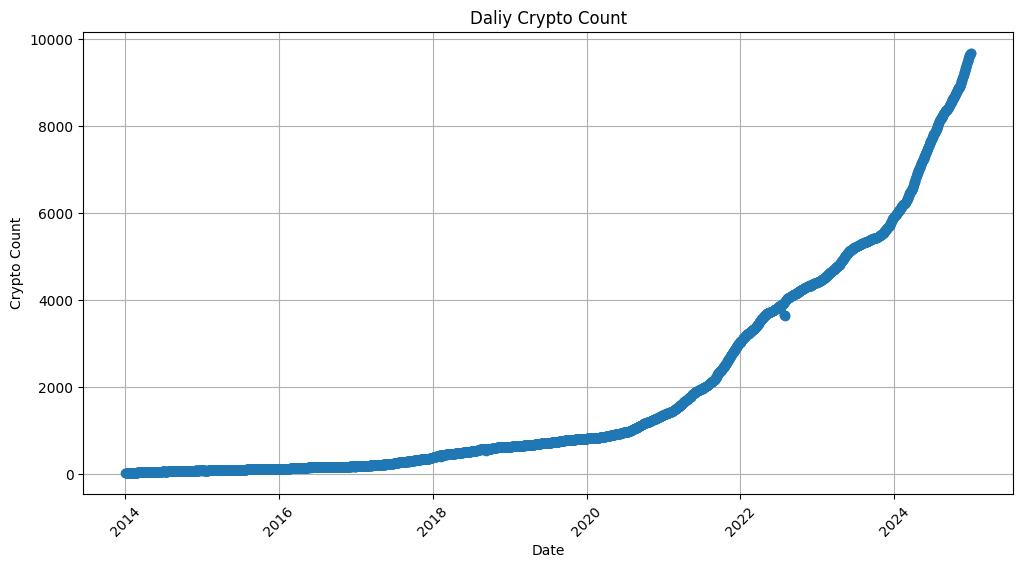

time_open
2014      85
2015     125
2016     178
2017     381
2018     627
2019     816
2020    1361
2021    3047
2022    4404
2023    5901
2024    9672
Name: id, dtype: int64


,id,ref_cur_id,time_open,open,high,low,close,volume,market_cap
count,7.844880e+06,7844880.0,7844880,7.844880e+06,7.844880e+06,7.844880e+06,7.844880e+06,7.844880e+06,7.844880e+06
mean,1.258635e+04,2781.0,2022-12-12 02:15:00.611250432,3.126084e+05,3.436867e+05,3.013465e+05,3.297908e+05,4.151303e+07,3.777902e+08
min,1.000000e+00,2781.0,2014-01-01 00:00:00,1.000000e-14,1.000000e-14,1.000000e-14,1.000000e-14,0.000000e+00,-1.414391e+09
25%,4.026000e+03,2781.0,2022-02-28 00:00:00,8.687722e-04,9.358218e-04,8.062564e-04,8.662552e-04,5.140400e+02,0.000000e+00
50%,1.026500e+04,2781.0,2023-06-09 00:00:00,1.449924e-02,1.551871e-02,1.355654e-02,1.446011e-02,3.299167e+04,0.000000e+00
75%,1.988600e+04,2781.0,2024-05-11 00:00:00,2.212077e-01,2.353395e-01,2.080763e-01,2.206861e-01,4.284395e+05,4.190895e+06
max,3.520200e+04,2781.0,2024-12-31 00:00:00,1.033749e+11,1.051383e+11,9.764522e+10,1.051383e+11,6.131225e+11,3.113963e+13
std,9.595446e+03,0.0,NaN,1.563207e+08,1.694492e+08,1.511663e+08,1.639684e+08,1.335448e+09,1.736928e+10


In [10]:

# 确保 time_open 是 datetime 类型
df['time_open'] = pd.to_datetime(df['time_open'])

# 计算每天的唯一 ID 数量
daily_id_counts = df.groupby('time_open')['id'].nunique()

# 确保 time_open 是 datetime 类型
df['time_open'] = pd.to_datetime(df['time_open']) 


# 按天统计 id 数量
daily_id_count = df.groupby(df['time_open'].dt.date)['id'].nunique()


# 计算每天的唯一 ID 数量
daily_id_counts = df.groupby('time_open')['id'].nunique()

# 计算每年中，每天唯一 ID 数量的最大值
yearly_max_daily_id_counts = daily_id_counts.groupby(daily_id_counts.index.year).max()

# 按天统计 id 数量
daily_id_count = df.groupby(df['time_open'].dt.date)['id'].nunique()

# 可视化
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(daily_id_count.index, daily_id_count.values, marker='o', linestyle='-')
plt.xlabel('Date')
plt.ylabel('Crypto Count')
plt.title('Daliy Crypto Count')
plt.xticks(rotation=45)
plt.grid()
plt.show()
print(yearly_max_daily_id_counts)
df.describe()

In [11]:
df_negative_market_cap = df[df['market_cap'] < 0]
df_negative_market_cap

,id,slug,name,symbol,timestamp,ref_cur_id,ref_cur_name,time_open,time_close,time_high,time_low,open,high,low,close,volume,market_cap
1313528,4286,zenzo,ZENZO,ZNZ,2021-05-30 23:59:59,2781,USD,2021-05-30,2021-05-30 23:59:59,2021-05-30 12:02:04,2021-05-30 00:44:03,0.055963,0.062067,0.054194,0.056153,185.42,-6.805000e+01
1313529,4286,zenzo,ZENZO,ZNZ,2021-05-31 23:59:59,2781,USD,2021-05-31,2021-05-31 23:59:59,2021-05-31 16:52:04,2021-05-31 02:23:04,0.056181,0.083934,0.054485,0.062882,671.96,-7.621000e+01
1313530,4286,zenzo,ZENZO,ZNZ,2021-06-01 23:59:59,2781,USD,2021-06-01,2021-06-01 23:59:59,2021-06-01 00:59:04,2021-06-01 16:59:04,0.062929,0.063837,0.056776,0.061725,1740.51,-7.481000e+01
1594558,8644,kylin,Kylin,KYL,2021-03-12 23:59:59,2781,USD,2021-03-12,2021-03-12 23:59:59,2021-03-12 23:38:06,2021-03-12 15:05:07,1.267470,1.606444,1.116953,1.571007,18488947.81,-1.414391e+09
2408891,9103,gamee,GAMEE,GMEE,2022-12-23 23:59:59,2781,USD,2022-12-23,2022-12-23 23:59:59,2022-12-23 03:03:00,2022-12-23 06:15:00,0.006008,0.006017,0.005896,0.005976,134958.52,-1.015183e+07
2408892,9103,gamee,GAMEE,GMEE,2022-12-24 23:59:59,2781,USD,2022-12-24,2022-12-24 23:59:59,2022-12-24 19:28:00,2022-12-24 07:18:00,0.005975,0.006045,0.005928,0.006006,75589.26,-1.020367e+07
2408893,9103,gamee,GAMEE,GMEE,2022-12-25 23:59:59,2781,USD,2022-12-25,2022-12-25 23:59:59,2022-12-25 12:43:00,2022-12-25 21:04:00,0.006006,0.006047,0.005970,0.005989,69478.80,-1.017439e+07


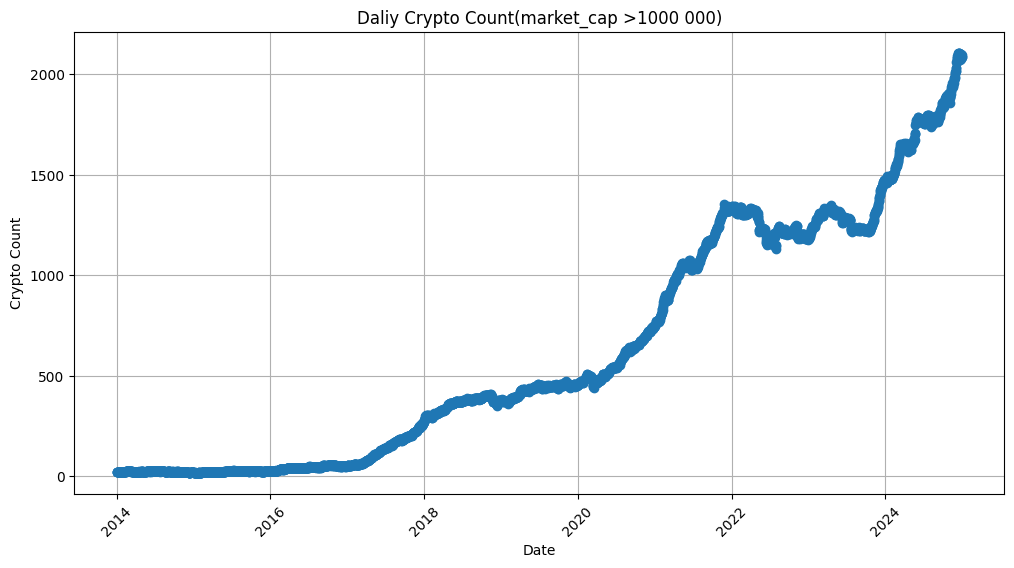

不存在 volume 为 0 的数据


time_open
2014      27
2015      28
2016      57
2017     271
2018     407
2019     472
2020     750
2021    1354
2022    1345
2023    1475
2024    2107
Name: id, dtype: int64

In [12]:
df = df.dropna(subset=['market_cap'])
df = df[df['market_cap'] > 1000000]
df = df[df['volume'] != 0]
# 计算每天的唯一 ID 数量
daily_id_counts = df.groupby('time_open')['id'].nunique()

# 计算每年中，每天唯一 ID 数量的最大值
yearly_max_daily_id_counts = daily_id_counts.groupby(daily_id_counts.index.year).max()

# 按天统计 id 数量
daily_id_count = df.groupby(df['time_open'].dt.date)['id'].nunique()

# 可视化
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(daily_id_count.index, daily_id_count.values, marker='o', linestyle='-')
plt.xlabel('Date')
plt.ylabel('Crypto Count')
plt.title('Daliy Crypto Count(market_cap >1000 000)')
plt.xticks(rotation=45)
plt.grid()
plt.show()
df.describe()
# 计算每天的唯一 ID 数量
daily_id_counts = df.groupby('time_open')['id'].nunique()

# 计算每年中，每天唯一 ID 数量的最大值
yearly_max_daily_id_counts = daily_id_counts.groupby(daily_id_counts.index.year).max()
yearly_max_daily_id_counts

# 检查是否有 volume 为 0 的数据
if (df['volume'] == 0).any():
    print("存在 volume 为 0 的数据")
else:
    print("不存在 volume 为 0 的数据")

# 或者直接查看所有 volume 为 0 的行
rows_with_zero_volume = df[df['volume'] == 0]
yearly_max_daily_id_counts

Weekly

In [6]:
import os
import glob
import pandas as pd

# 指定文件夹路径
folder_path = r"D:\桌面\绿色货币\数据总库\R数据抓取加密货币数据"

# 获取所有符合条件的 CSV 文件路径并读取合并
file_paths = sorted(glob.glob(os.path.join(folder_path, "crypto_full_*_7d_data.csv")))
df_week = pd.concat((pd.read_csv(file) for file in file_paths), ignore_index=True)

In [7]:
df_week = df_week.dropna(subset=['market_cap'])
df_week = df_week[df_week['market_cap'] > 1000000]
df_week = df_week[df_week["volume"] != 0]
# 计算每天的唯一 ID 数量
daily_id_counts = df_week.groupby('time_open')['id'].nunique()

# 计算每年中，每天唯一 ID 数量的最大值
yearly_max_daily_id_counts = daily_id_counts.groupby(daily_id_counts.index.year).max()

# 按天统计 id 数量
daily_id_count = df_week.groupby(df_week['time_open'].dt.date)['id'].nunique()

# 可视化
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(daily_id_count.index, daily_id_count.values, marker='o', linestyle='-')
plt.xlabel('Date')
plt.ylabel('Crypto Count')
plt.title('Daliy Crypto Count(market_cap >1000 000)')
plt.xticks(rotation=45)
plt.grid()
plt.show()
df_week.describe()
# 计算每天的唯一 ID 数量
daily_id_counts = df_week.groupby('time_open')['id'].nunique()

# 计算每年中，每天唯一 ID 数量的最大值
yearly_max_daily_id_counts = daily_id_counts.groupby(daily_id_counts.index.year).max()
yearly_max_daily_id_counts

# 检查是否有 volume 为 0 的数据
if (df_week['volume'] == 0).any():
    print("存在 volume 为 0 的数据")
else:
    print("不存在 volume 为 0 的数据")

# 或者直接查看所有 volume 为 0 的行
rows_with_zero_volume = df_week[df_week['volume'] == 0]
yearly_max_daily_id_counts

AttributeError: 'Index' object has no attribute 'year'

In [7]:
df_negative_market_cap = df_week[df_week['market_cap'] < 0]
df_negative_market_cap

,id,slug,name,symbol,timestamp,ref_cur_id,ref_cur_name,time_open,time_close,time_high,time_low,open,high,low,close,volume,market_cap
294071,4286,zenzo,ZENZO,ZNZ,2021-05-30 23:59:59,2781,USD,2021-05-24,2021-05-30 23:59:59,2021-05-25 14:27:04,2021-05-27 21:39:04,0.05919,0.089724,0.051188,0.056153,6274.65,-68.05


In [34]:
# 提取所有年份
years = sorted(set(df['time_open'].dt.year) | set(df_week['time_open'].dt.year))

# 记录每年的缺失情况
missing_summary = []

# 遍历每个年份进行比较
for year in years:
    df_year = df[df['time_open'].dt.year == year]
    df_weekly_year = df_week[df_week['time_open'].dt.year == year]

    # 获取当年唯一 ID
    ids_df = set(df_year['id'].unique())
    ids_df_weekly = set(df_weekly_year['id'].unique())

    # 计算差异
    missing_in_weekly = ids_df.difference(ids_df_weekly)  # df 有但 df_weekly 没有
    missing_in_df = ids_df_weekly.difference(ids_df)  # df_weekly 有但 df 没有

    # 记录结果
    missing_summary.append({
        "year": year,
        "missing_in_weekly_count": len(missing_in_weekly),
        "missing_in_df_count": len(missing_in_df),
        "missing_in_weekly_sample": list(missing_in_weekly),
        "missing_in_df_sample": list(missing_in_df)
    })

# 转换为 DataFrame 方便查看
missing_df = pd.DataFrame(missing_summary)

missing_df.to_csv("missing_df.csv")

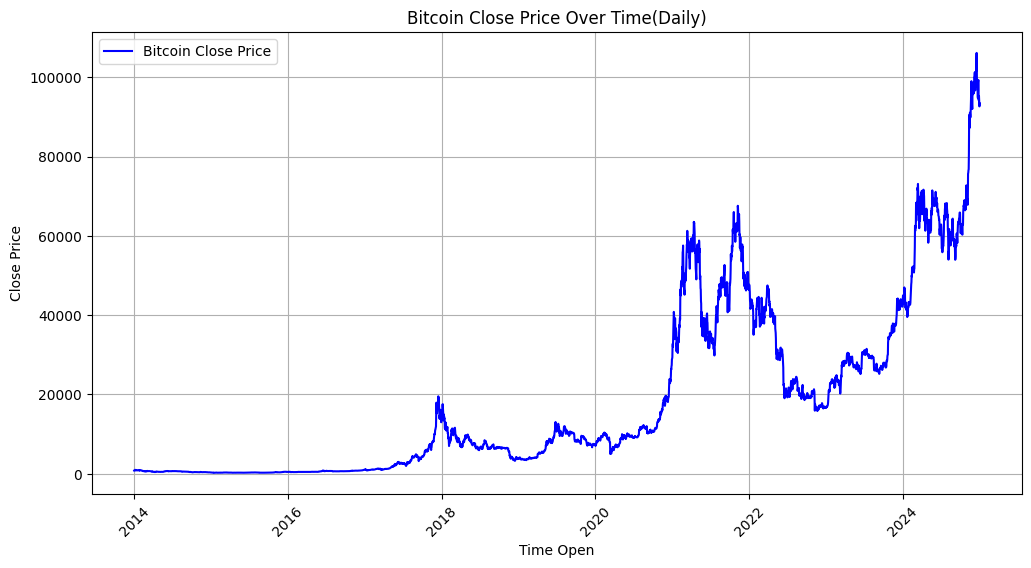

In [33]:
import matplotlib.pyplot as plt

# 确保 time_open 是 datetime 类型
df['time_open'] = pd.to_datetime(df['time_open'])

# 过滤出 symbol 为 'bitcoin' 的数据
bitcoin_df = df[df['name'] == 'Bitcoin']

# 按时间排序（确保时间顺序正确）
bitcoin_df = bitcoin_df.sort_values(by='time_open')

# 绘制 close 价格随时间的趋势
plt.figure(figsize=(12, 6))
plt.plot(bitcoin_df['time_open'], bitcoin_df['close'], label='Bitcoin Close Price', color='blue')

# 添加标题和标签
plt.title('Bitcoin Close Price Over Time(Daily)')
plt.xlabel('Time Open')
plt.ylabel('Close Price')
plt.legend()
plt.xticks(rotation=45)  # 旋转 X 轴时间刻度，提高可读性
plt.grid(True)

# 显示图像
plt.show()

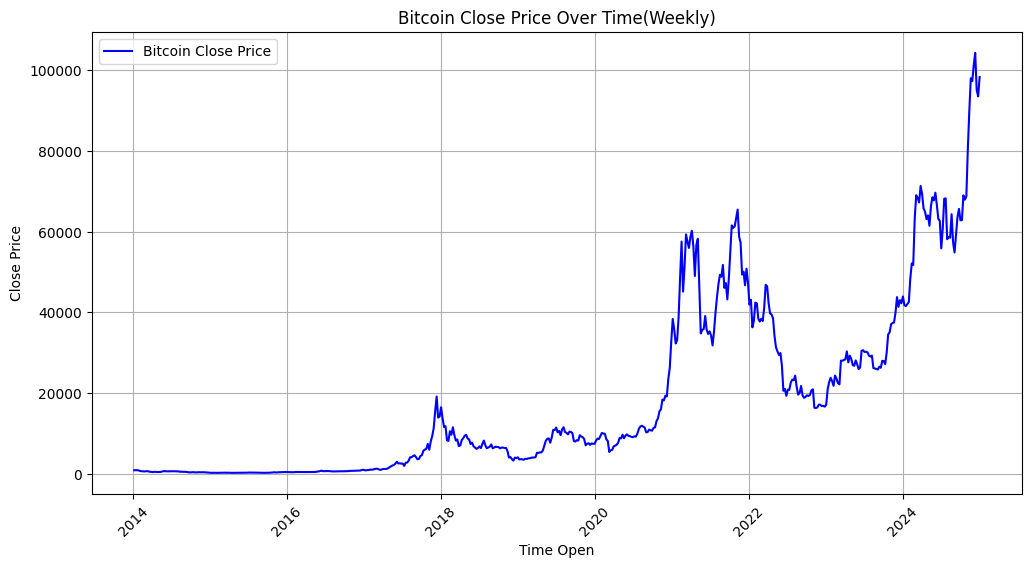

time_open
7 days    573
Name: count, dtype: int64


In [32]:
import matplotlib.pyplot as plt

# 确保 time_open 是 datetime 类型
df_week['time_open'] = pd.to_datetime(df_week['time_open'])

# 过滤出 symbol 为 'bitcoin' 的数据
bitcoin_df_week = df_week[df_week['name'] == 'Bitcoin']

# 按时间排序（确保时间顺序正确）
bitcoin_df_week = bitcoin_df_week.sort_values(by='time_open')

# 绘制 close 价格随时间的趋势
plt.figure(figsize=(12, 6))
plt.plot(bitcoin_df_week['time_open'], bitcoin_df_week['close'], label='Bitcoin Close Price', color='blue')

# 添加标题和标签
plt.title('Bitcoin Close Price Over Time(Weekly)')
plt.xlabel('Time Open')
plt.ylabel('Close Price')
plt.legend()
plt.xticks(rotation=45)  # 旋转 X 轴时间刻度，提高可读性
plt.grid(True)

# 显示图像
plt.show()
print(bitcoin_df_week['time_open'].diff().value_counts().head(10))